# 🎯 Smart Recruitment Assistant — Final
### AI-Based Candidate Screening & Ranking System

**Graduation Project — Artificial Intelligence Professional Diploma**
**Project 2 — HR Analytics: Job Change of Data Scientists**

---

## Objective
Recruiters receive hundreds of applications per vacancy. This notebook builds, tunes and evaluates a
machine-learning system that predicts whether a candidate is actively looking for a job change, so
recruiters can prioritize outreach where it matters most.

## Methodology highlights
- **Leakage-free design** — the train/validation/test split happens *before* median imputation,
  feature engineering, city-frequency encoding, scaling and threshold tuning, so every fitted
  statistic is derived from training data only. The test set is touched exactly once, at final
  evaluation, and the champion model is selected on **validation AUPRC**, never on the test set.
- **Held-out protocol** — Train (64%) / Validation (16%) / Test (20%), all stratified.
  The validation set is used *only* to tune decision thresholds and to pick the champion.
- **Unified evaluation** — One threshold-tuning procedure (F1-maximizing point on the
  precision-recall curve) applied identically to every model.
- **Four models** — Logistic Regression (linear baseline), Random Forest, XGBoost and
  (optionally) LightGBM, with bounded hyperparameter search and 5-fold cross-validation
  for robustness.

## Notebook structure
1. Data Loading & First Look
2. Missing Value Analysis
3. Data Cleaning & Preprocessing
4. Train / Validation / Test Split
5. Feature Engineering
6. Encoding Strategy (train-fit only)
7. Exploratory Data Analysis (EDA)
8. Unified Threshold Tuning
9. Model 1 — Logistic Regression
10. Model 2 — Random Forest (tuned)
11. Model 3 — XGBoost (tuned)
12. Model 4 — LightGBM (optional)
13. Model Comparison & Evaluation
14. Cross-Validation Robustness Check
15. Business Insights — Most Important Hiring Factors
16. Bonus — Candidate Ranking System (on unseen candidates)
17. Conclusions & Recommendations
18. Data Citation & Saved Artifacts (for deployment)
---

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score
)

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
})

PRIMARY   = "#1E2761"
ACCENT    = "#F96167"
SECONDARY = "#CADCFC"
PALETTE   = [PRIMARY, ACCENT]
SERIES    = [PRIMARY, ACCENT, "#5D8AA8", "#2E8B57", "#8B5E83"]

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
print("Environment ready  |  sklearn", __import__("sklearn").__version__)

Environment ready  |  sklearn 1.9.1


## 1. Data Loading & First Look

In [2]:
CANDIDATE_PATHS = [
    "aug_train.csv",
    "/content/aug_train.csv",
    "archive/aug_train.csv",
    "../project/archive/aug_train.csv",
]

df = None
for path in CANDIDATE_PATHS:
    try:
        df = pd.read_csv(path)
        print(f"Loaded from: {path}")
        break
    except FileNotFoundError:
        pass
if df is None:
    raise FileNotFoundError("aug_train.csv — place it next to this notebook or upload it to Colab")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Loaded from: aug_train.csv
Dataset shape: 19,158 rows × 14 columns


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  str    
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  str    
 4   relevent_experience     19158 non-null  str    
 5   enrolled_university     18772 non-null  str    
 6   education_level         18698 non-null  str    
 7   major_discipline        16345 non-null  str    
 8   experience              19093 non-null  str    
 9   company_size            13220 non-null  str    
 10  company_type            13018 non-null  str    
 11  last_new_job            18735 non-null  str    
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), str(10)
memory usage: 3.

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,NaN,NaN,NaN,16875.358179,9616.292592,1.0,8554.25,16982.5,25169.75,33380.0
city,19158,123,city_103,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_development_index,19158.0,NaN,NaN,NaN,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
gender,14650,3,Male,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relevent_experience,19158,2,Has relevent experience,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enrolled_university,18772,3,no_enrollment,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,18698,5,Graduate,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
major_discipline,16345,6,STEM,14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience,19093,22,>20,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,13220,8,50-99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Missing Value Analysis

Several columns contain missing entries. Before deciding how to treat each one, we quantify the
scale of missingness across the dataset.

In [5]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0]
missing_df

,Missing Count,Missing %
company_type,6140,32.05
company_size,5938,30.99
gender,4508,23.53
major_discipline,2813,14.68
education_level,460,2.40
last_new_job,423,2.21
enrolled_university,386,2.01
experience,65,0.34


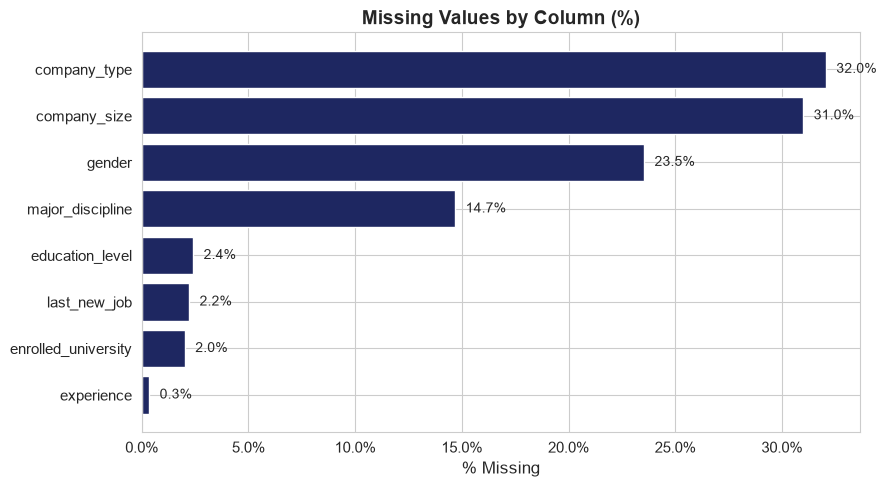

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(missing_df.index[::-1], missing_df["Missing %"][::-1], color=PRIMARY)
ax.set_title("Missing Values by Column (%)")
ax.set_xlabel("% Missing")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=10)
plt.tight_layout()
plt.show()

**Decision:** `company_type` and `company_size` have the highest missingness (~32%), followed by
`gender` (~24%). These are categorical fields where "missing" itself may carry signal (e.g. a
candidate declining to state their company type), so we impute them with an explicit
`"UNKNOWN"` category rather than dropping rows — preserving the full dataset (19,158 candidates).

`experience` and `last_new_job` are ordinal text fields (`">20"`, `"<1"`, `">4"`, `"never"`) with low
missingness (<5%), so they are converted to numeric. Because median imputation is a *fitted*
statistic, their missing entries are filled with the **training-split median** — computed after
the split in Section 4, never from validation or test rows.

## 3. Data Cleaning & Preprocessing

Only *deterministic* transformations are applied in this section — no fitted statistics:
- Convert ordinal text values (`">20"` → `21`, `"<1"` → `0`, `">4"` → `5`, `"never"` → `0`) — these are
  value mappings, not statistics
- Fix the `company_size` typo (`"10/49"` → `"10-49"`)
- Impute categorical gaps with an explicit `"UNKNOWN"` category

The two median fills for `experience` and `last_new_job` are deferred to Section 5, after the split,
so they are computed from training rows only.

In [7]:
df["experience"] = df["experience"].replace({"ERROR": np.nan, ">20": "21", "<1": "0"})
df["experience"] = pd.to_numeric(df["experience"])

df["last_new_job"] = df["last_new_job"].replace({"ERROR": np.nan, ">4": "5", "never": "0"})
df["last_new_job"] = pd.to_numeric(df["last_new_job"])

df["company_size"] = df["company_size"].replace("10/49", "10-49")

for col in ["gender", "education_level", "enrolled_university",
            "major_discipline", "company_size", "company_type"]:
    df[col] = df[col].fillna("UNKNOWN")

print("Deterministic cleaning done — no fitted statistics used.")
print("Remaining NaN (to be filled with the train-split median after the split):")
print(f"  experience   : {int(df['experience'].isnull().sum())}")
print(f"  last_new_job : {int(df['last_new_job'].isnull().sum())}")
print("company_size values:", sorted(df["company_size"].unique()))

Deterministic cleaning done — no fitted statistics used.
Remaining NaN (to be filled with the train-split median after the split):
  experience   : 65
  last_new_job : 423
company_size values: ['10-49', '100-500', '1000-4999', '10000+', '50-99', '500-999', '5000-9999', '<10', 'UNKNOWN']


## 4. Train / Validation / Test Split (before any fitted statistic)

The split happens **before** median imputation, feature engineering and encoding, so every fitted
statistic in the notebook — medians, city frequencies, scaling, thresholds — is learned from
training data only:
- **Test (20%)** — untouched until the very final evaluation
- **Validation (16%)** — used *only* to tune decision thresholds and pick the champion
- **Train (64%)** — the single source for all fitted statistics and cross-validated search

All three splits are stratified on the target.

In [8]:
feature_cols = [c for c in df.columns if c not in ["enrollee_id", "target"]]
X = df[feature_cols]
y = df["target"]

X_raw_train_full, X_raw_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_raw_train, X_raw_val, y_train, y_val = train_test_split(
    X_raw_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# The only two fitted statistics in the whole pipeline so far — both computed on TRAIN rows only:
experience_median = X_raw_train["experience"].median()
last_new_job_median = X_raw_train["last_new_job"].median()

print(f"Train: {X_raw_train.shape}   Val: {X_raw_val.shape}   Test: {X_raw_test.shape}")
print(f"Train-fit medians  ->  experience: {experience_median}, last_new_job: {last_new_job_median}")

Train: (12260, 12)   Val: (3066, 12)   Test: (3832, 12)
Train-fit medians  ->  experience: 9.0, last_new_job: 1.0


## 5. Feature Engineering

Applied to each split with the training medians already filled — derived features often carry more
predictive signal than the raw fields alone because they capture career dynamics rather than static
credentials:

In [9]:
def experience_bucket(x):
    if x <= 3:
        return 0
    elif x <= 9:
        return 1
    return 2


def engineer(frame, exp_median, lnj_median):
    """Row-wise feature engineering (no cross-row statistics)."""
    out = frame.copy()
    out["experience"] = out["experience"].fillna(exp_median)
    out["last_new_job"] = out["last_new_job"].fillna(lnj_median)
    out["experience_level"] = out["experience"].apply(experience_bucket)
    out["is_recent_mover"] = ((out["last_new_job"] <= 1) & (out["experience"] > 1)).astype(int)
    out["training_per_experience"] = out["training_hours"] / (out["experience"] + 1)
    out["experience_x_cdi"] = out["experience"] * out["city_development_index"]
    return out


X_train = engineer(X_raw_train, experience_median, last_new_job_median)
X_val = engineer(X_raw_val, experience_median, last_new_job_median)
X_test = engineer(X_raw_test, experience_median, last_new_job_median)

new_features = ["experience_level", "is_recent_mover", "training_per_experience", "experience_x_cdi"]
print("Engineered features:", new_features)
print(f"Train: {X_train.shape}   Val: {X_val.shape}   Test: {X_test.shape}")
X_train[new_features].round(2).describe()

Engineered features: ['experience_level', 'is_recent_mover', 'training_per_experience', 'experience_x_cdi']
Train: (12260, 16)   Val: (3066, 16)   Test: (3832, 16)


,experience_level,is_recent_mover,training_per_experience,experience_x_cdi
count,12260.000000,12260.000000,12260.000000,12260.000000
mean,1.266966,0.515090,10.215555,8.649083
std,0.753339,0.499793,17.190869,6.205512
min,0.000000,0.000000,0.080000,0.000000
25%,1.000000,0.000000,2.190000,3.540000
50%,1.000000,1.000000,5.000000,6.980000
75%,2.000000,1.000000,11.415000,13.800000
max,2.000000,1.000000,336.000000,19.930000


## 6. Encoding Strategy (train-fit only)

| Column | Encoding | Rationale |
|---|---|---|
| `city` | **Frequency encoding** (train-fit) | ~123 nominal cities; Label Encoding would impose a fake numeric order between cities |
| `relevent_experience` | Binary 0/1 map | Two intuitive classes |
| `education_level` | Ordinal map | Genuine order: Primary → High School → Graduate → Masters → Phd |
| `company_size` | Ordinal map | Genuine order: <10 → 10-49 → … → 10000+ |
| `gender`, `enrolled_university`, `major_discipline`, `company_type` | One-hot | Small nominal cardinality, no fake ordering |

Encoding is fitted on the **training split only**; unseen categories in validation/test map to 0.

In [10]:
city_freq = X_train["city"].value_counts(normalize=True)

ORDINAL_EDU = {
    "UNKNOWN": 0,
    "Primary School": 1,
    "High School": 2,
    "Graduate": 3,
    "Masters": 4,
    "Phd": 5,
}
ORDINAL_SIZE = {
    "UNKNOWN": 0,
    "<10": 1, "10-49": 2, "50-99": 3, "100-500": 4,
    "500-999": 5, "1000-4999": 6, "5000-9999": 7, "10000+": 8,
}
ONEHOT_COLS = ["gender", "enrolled_university", "major_discipline", "company_type"]


def encode_features(X_part):
    out = X_part.copy()
    out["city_frequency"] = out["city"].map(city_freq).fillna(0.0)
    out = out.drop(columns=["city"])
    out["relevent_experience"] = out["relevent_experience"].map(
        {"Has relevent experience": 1, "No relevent experience": 0}
    )
    out["education_level"] = out["education_level"].map(ORDINAL_EDU).fillna(0)
    out["company_size"] = out["company_size"].map(ORDINAL_SIZE).fillna(0)
    out = pd.get_dummies(out, columns=ONEHOT_COLS, dtype=int)
    return out


X_train_enc = encode_features(X_train)
feature_names = X_train_enc.columns.tolist()
X_val_enc = encode_features(X_val).reindex(columns=feature_names, fill_value=0)
X_test_enc = encode_features(X_test).reindex(columns=feature_names, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)
X_val_scaled = scaler.transform(X_val_enc)
X_test_scaled = scaler.transform(X_test_enc)

X_train_arr = X_train_enc.to_numpy()
X_val_arr = X_val_enc.to_numpy()
X_test_arr = X_test_enc.to_numpy()

print(f"Encoded features: {len(feature_names)}")
print("Train:", X_train_enc.shape, " Val:", X_val_enc.shape, " Test:", X_test_enc.shape)

Encoded features: 34
Train: (12260, 34)  Val: (3066, 34)  Test: (3832, 34)


## 7. Exploratory Data Analysis (EDA)

Plots use the cleaned dataset; the correlation heatmap uses the **training split only** (keeping
all EDA statistics trainable-data-derived).

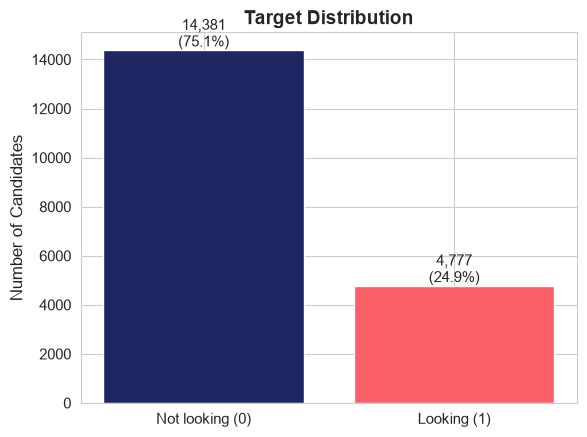

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
counts = df["target"].value_counts().sort_index()
labels = ["Not looking (0)", "Looking (1)"]
bars = ax.bar(labels, counts.values, color=PALETTE)
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 150, f"{v:,}\n({v / counts.sum() * 100:.1f}%)",
            ha="center", fontsize=11)
ax.set_title("Target Distribution")
ax.set_ylabel("Number of Candidates")
plt.tight_layout()
plt.show()

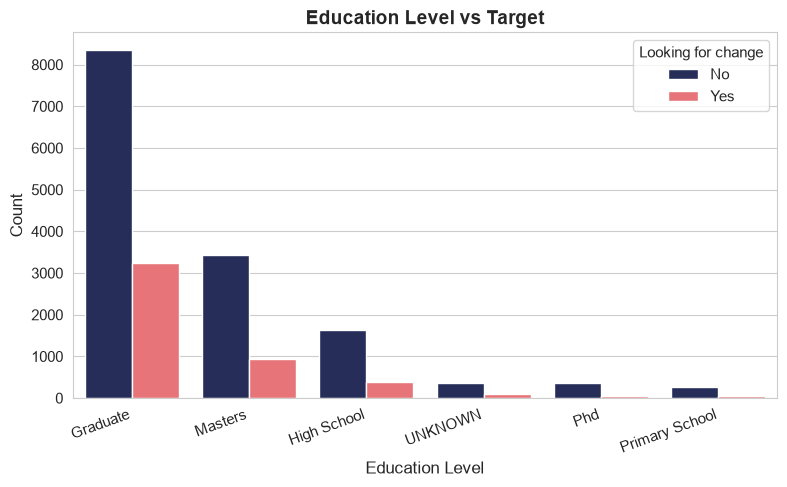

In [12]:
order = df["education_level"].value_counts().index
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(x="education_level", hue="target", data=df, order=order, palette=PALETTE, ax=ax)
ax.set_title("Education Level vs Target")
ax.set_xlabel("Education Level")
ax.set_ylabel("Count")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(title="Looking for change", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

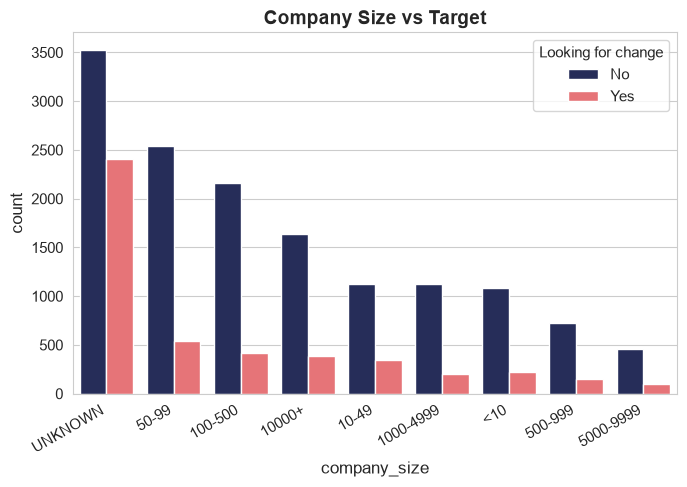

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(x="company_size", hue="target", data=df,
              order=df["company_size"].value_counts().index, palette=PALETTE, ax=ax)
ax.set_title("Company Size vs Target")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(title="Looking for change", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

**Candidate profile trends & recruitment statistics:**

Beyond the two raw feature charts above, we quantify intent rates across the career and
geography dimensions — the practical analogue of the "most important hiring factors" insight that
follows later (Section 15).

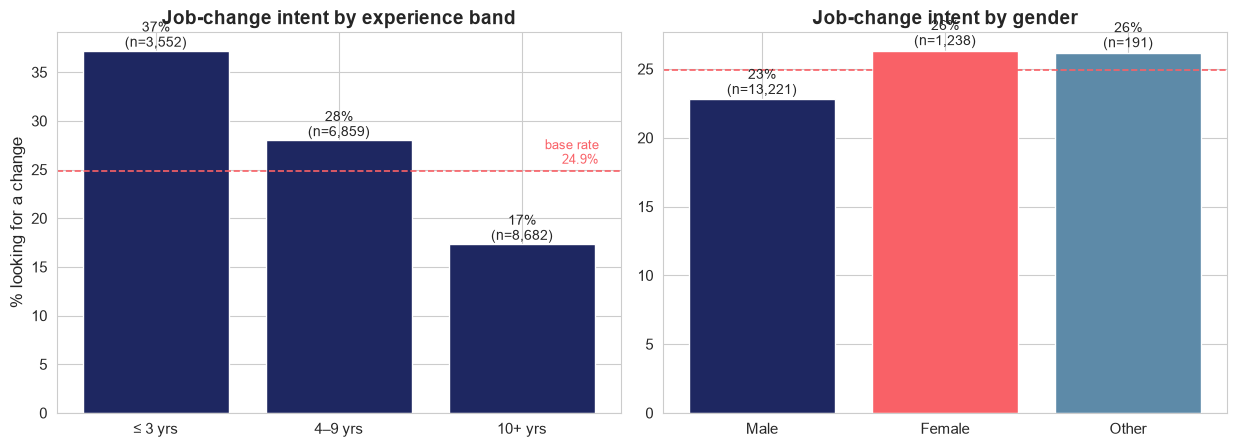

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

# --- experience band vs intent ---
exp_band = df.dropna(subset=["experience"]).assign(
    band=df.dropna(subset=["experience"])["experience"].apply(experience_bucket)
).groupby("band")["target"].agg(["count", "mean"])
exp_labels = {0: "\u2264 3 yrs", 1: "4\u20139 yrs", 2: "10+ yrs"}
axes[0].bar([exp_labels[b] for b in exp_band.index],
            exp_band["mean"] * 100, color=PRIMARY)
for i, (n, v) in enumerate(zip(exp_band["count"], exp_band["mean"] * 100)):
    axes[0].text(i, v + 0.4, f"{v:.0f}%\n(n={int(n):,})", ha="center", fontsize=10)
axes[0].set_title("Job-change intent by experience band")
axes[0].set_ylabel("% looking for a change")
axes[0].axhline(24.9, color=ACCENT, ls="--", lw=1.2)
axes[0].text(2.42, 25.6, "base rate\n24.9%", color=ACCENT, fontsize=9, ha="right")

# --- gender vs intent ---
gender_rate = df.groupby("gender")["target"].agg(["count", "mean"]).loc[["Male", "Female", "Other"]]
axes[1].bar(gender_rate.index, gender_rate["mean"] * 100,
            color=[PRIMARY, ACCENT, "#5D8AA8"])
for i, (n, v) in enumerate(zip(gender_rate["count"], gender_rate["mean"] * 100)):
    axes[1].text(i, v + 0.4, f"{v:.0f}%\n(n={int(n):,})", ha="center", fontsize=10)
axes[1].set_title("Job-change intent by gender")
axes[1].axhline(24.9, color=ACCENT, ls="--", lw=1.2)

plt.tight_layout()
plt.show()

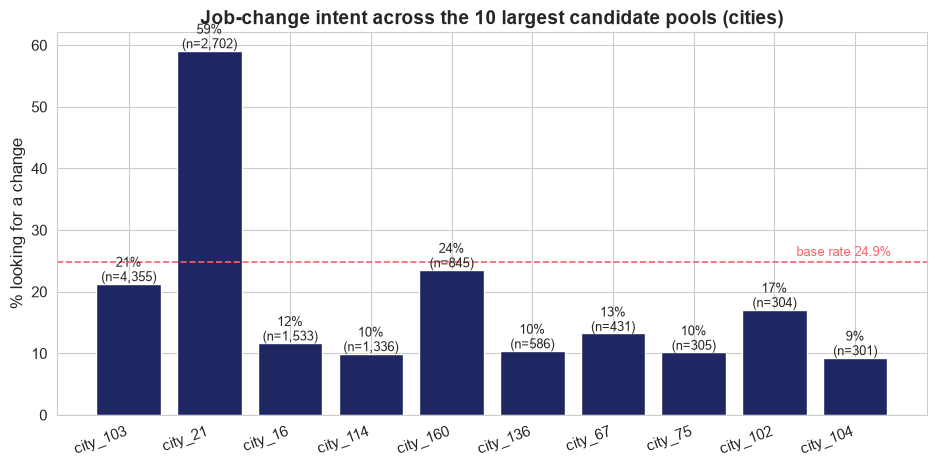

Recruitment statistics snapshot (highest/lowest volume cities):


,profiles,mean_target,pct_looking
city,,,
city_103,4355,0.213088,21.3
city_21,2702,0.591044,59.1
city_16,1533,0.116765,11.7
city_114,1336,0.099551,10.0
city_160,845,0.235503,23.6
city_136,586,0.104096,10.4
city_67,431,0.132251,13.2
city_75,305,0.101639,10.2
city_102,304,0.171053,17.1


In [15]:
city_stats = df.groupby("city")["target"].agg(["count", "mean"])
top_cities = city_stats.sort_values("count", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(top_cities.index, top_cities["mean"] * 100, color=PRIMARY)
ax.axhline(24.9, color=ACCENT, ls="--", lw=1.2)
ax.text(9.45, 25.8, "base rate 24.9%", color=ACCENT, fontsize=9, ha="right")
for bar, n in zip(bars, top_cities["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            f"{bar.get_height():.0f}%\n(n={int(n):,})", ha="center", fontsize=9)
ax.set_title("Job-change intent across the 10 largest candidate pools (cities)")
ax.set_ylabel("% looking for a change")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Recruitment statistics snapshot (highest/lowest volume cities):")
display(top_cities.assign(pct_looking=(top_cities["mean"] * 100).round(1))
         .rename(columns={"mean": "mean_target", "count": "profiles"}))

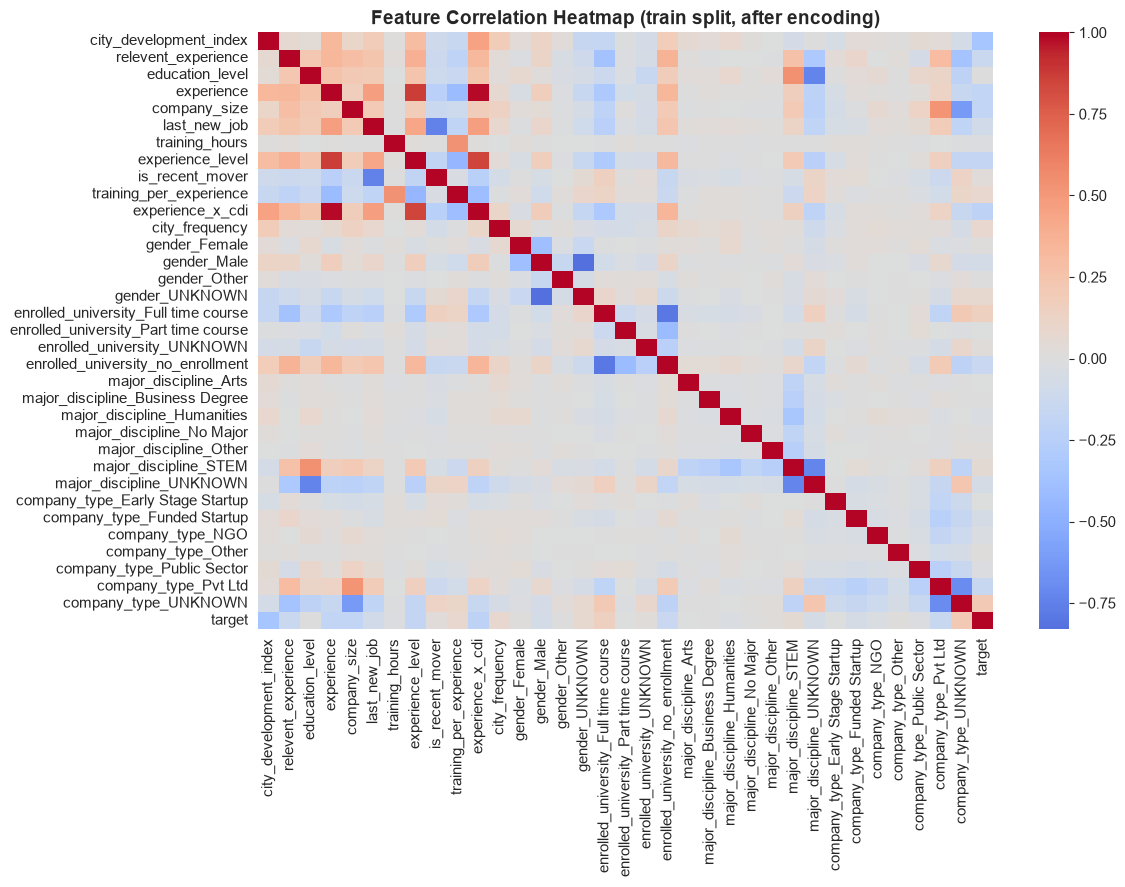

In [16]:
train_viz = X_train_enc.copy()
train_viz["target"] = y_train.values
corr = train_viz.corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, ax=ax)
ax.set_title("Feature Correlation Heatmap (train split, after encoding)")
plt.tight_layout()
plt.show()

**EDA takeaways:**
- The target is imbalanced (~75% / 25%) — addressed via `class_weight` / `scale_pos_weight`
  rather than synthetic oversampling, which keeps every training observation real.
- Candidates with Graduate education dominate both classes; education alone is a weak signal.
- Candidates at small/unknown-size companies show a visibly higher rate of looking for a change.
- City tier is a strong context signal: in the 10 largest candidate pools, `city_21` (2,702
  profiles) shows a 59.1% job-change rate against 21.3% in `city_103` (4,355 profiles) — later
  confirmed by the champion model, where the city measures carry ~36% of total feature importance.
- No single raw feature correlates strongly with the target — this favors non-linear models that
  capture feature interactions.

## 8. Unified Threshold Tuning

Instead of guessing a cutoff, every model's probability threshold is picked from the
**precision-recall curve on the validation set** (F1-maximizing point) — the same procedure,
identically applied to every model. The test set never influences this choice.

In [17]:
def best_threshold(y_true, y_proba):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
    best_idx = int(np.argmax(f1_scores[:-1]))
    return float(thresholds[best_idx]), float(f1_scores[best_idx])


RESULTS = {}


def evaluate_model(name, model, X_val_matrix, X_test_matrix):
    val_proba = model.predict_proba(X_val_matrix)[:, 1]
    threshold, val_f1 = best_threshold(y_val, val_proba)
    val_ap = average_precision_score(y_val, val_proba)

    test_proba = model.predict_proba(X_test_matrix)[:, 1]
    test_pred = (test_proba >= threshold).astype(int)

    print(f"{name}")
    print(f"  Threshold : {threshold:.3f}   (F1-maximizing point on validation PR curve)")
    print(f"  Val  F1   : {val_f1:.3f}   Val AUPRC: {val_ap:.3f}")
    print(f"  Accuracy  : {accuracy_score(y_test, test_pred):.3f}")
    print(f"  Precision : {precision_score(y_test, test_pred):.3f}")
    print(f"  Recall    : {recall_score(y_test, test_pred):.3f}")
    print(f"  F1 Score  : {f1_score(y_test, test_pred):.3f}")
    print(f"  ROC AUC   : {roc_auc_score(y_test, test_proba):.3f}")

    RESULTS[name] = dict(model=model, threshold=threshold, val_f1=val_f1,
                         val_ap=val_ap, proba=test_proba, pred=test_pred)
    return RESULTS[name]

---
## 9. Model 1 — Logistic Regression

A regularized linear baseline trained on standardized features. `class_weight="balanced"`
compensates for the imbalanced target.

In [18]:
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
evaluate_model("Logistic Regression", log_reg, X_val_scaled, X_test_scaled)

Logistic Regression
  Threshold : 0.562   (F1-maximizing point on validation PR curve)
  Val  F1   : 0.582   Val AUPRC: 0.502
  Accuracy  : 0.777
  Precision : 0.539
  Recall    : 0.715
  F1 Score  : 0.615
  ROC AUC   : 0.803


{'model': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
 'threshold': 0.56181470929087,
 'val_f1': 0.5821917803299458,
 'val_ap': 0.5023637124858149,
 'proba': array([0.12078701, 0.87459426, 0.07528126, ..., 0.49597018, 0.15135152,
        0.1817834 ], shape=(3832,)),
 'pred': array([0, 1, 0, ..., 0, 0, 0], shape=(3832,))}

---
## 10. Model 2 — Random Forest (tuned)

An ensemble of decision trees suited to the non-linear interactions observed in EDA.
A bounded cross-validated search (3-fold, training data only) selects depth and leaf size;
`class_weight` handles the class imbalance.

In [19]:
rf_grid = GridSearchCV(
    RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    param_grid={"max_depth": [10, 14, None], "min_samples_leaf": [1, 5]},
    scoring="roc_auc", cv=3, n_jobs=-1
)
rf_grid.fit(X_train_arr, y_train)
print("Best params:", rf_grid.best_params_)
rf_model = rf_grid.best_estimator_
evaluate_model("Random Forest", rf_model, X_val_arr, X_test_arr)

Best params: {'max_depth': 10, 'min_samples_leaf': 5}


Random Forest
  Threshold : 0.483   (F1-maximizing point on validation PR curve)
  Val  F1   : 0.610   Val AUPRC: 0.531
  Accuracy  : 0.793
  Precision : 0.561
  Recall    : 0.775
  F1 Score  : 0.651
  ROC AUC   : 0.815


{'model': RandomForestClassifier(class_weight='balanced_subsample', max_depth=10,
                        min_samples_leaf=5, n_estimators=300, n_jobs=-1,
                        random_state=42),
 'threshold': 0.48264876834793424,
 'val_f1': 0.6099210818093462,
 'val_ap': 0.5310129920430264,
 'proba': array([0.171919  , 0.77082192, 0.14523128, ..., 0.30005501, 0.21757559,
        0.15373457], shape=(3832,)),
 'pred': array([0, 1, 0, ..., 0, 0, 0], shape=(3832,))}

---
## 11. Model 3 — XGBoost (tuned)

Gradient boosting typically sets the benchmark on this dataset. `scale_pos_weight`
(computed on training data) compensates for the class imbalance; a bounded
3-fold search tunes depth and learning rate.

In [20]:
spw = float((y_train == 0).sum() / (y_train == 1).sum())

xgb_grid = GridSearchCV(
    XGBClassifier(
        n_estimators=300, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9,
        min_child_weight=5, tree_method="hist", eval_metric="logloss",
        scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1
    ),
    param_grid={"max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1]},
    scoring="roc_auc", cv=3, n_jobs=1
)
xgb_grid.fit(X_train_arr, y_train)
print("Best params:", xgb_grid.best_params_)
xgb_model = xgb_grid.best_estimator_
evaluate_model("XGBoost", xgb_model, X_val_arr, X_test_arr)

Best params: {'learning_rate': 0.05, 'max_depth': 4}
XGBoost
  Threshold : 0.553   (F1-maximizing point on validation PR curve)
  Val  F1   : 0.609   Val AUPRC: 0.512
  Accuracy  : 0.797
  Precision : 0.570
  Recall    : 0.756
  F1 Score  : 0.650
  ROC AUC   : 0.817


{'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.9, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=0.05, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=4, max_leaves=None,
               min_child_weight=5, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=300, n_jobs=-1,
               num_parallel_tree=None, ...),
 'threshold': 0.5531508922576904,
 'val_f1': 0.6087949738083647,
 'val_ap': 0.5121318514687117,
 'proba': array([0.07600325, 0.85416925, 0.07788435, ..., 0.31405336, 0.0522416 ,
        0.10401516], shape=(383

---
## 12. Model 4 — LightGBM (optional)

LightGBM is pre-installed in Colab; if unavailable locally the notebook continues gracefully.

In [21]:
try:
    from lightgbm import LGBMClassifier
    lgbm_model = LGBMClassifier(
        n_estimators=300, learning_rate=0.08, num_leaves=31,
        scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    )
    lgbm_model.fit(X_train_arr, y_train)
    evaluate_model("LightGBM", lgbm_model, X_val_arr, X_test_arr)
except ImportError:
    print("LightGBM not installed locally — skipped. (Available by default in Colab.)")

LightGBM not installed locally — skipped. (Available by default in Colab.)


## 13. Model Comparison & Evaluation

In [22]:
rows = []
for name, r in RESULTS.items():
    rows.append({
        "Model": name,
        "Threshold": r["threshold"],
        "Accuracy": accuracy_score(y_test, r["pred"]),
        "Precision": precision_score(y_test, r["pred"]),
        "Recall": recall_score(y_test, r["pred"]),
        "F1 Score": f1_score(y_test, r["pred"]),
        "ROC AUC": roc_auc_score(y_test, r["proba"]),
        "Val AUPRC": r["val_ap"],
    })

# IMPORTANT: the champion is selected on the VALIDATION metric (AUPRC) — the test-set numbers in
# this table are reported afterwards, but they never influence the choice.
results = pd.DataFrame(rows).sort_values("Val AUPRC", ascending=False).reset_index(drop=True)
results.round(3)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC AUC,Val AUPRC
0,Random Forest,0.483,0.793,0.561,0.775,0.651,0.815,0.531
1,XGBoost,0.553,0.797,0.570,0.756,0.650,0.817,0.512
2,Logistic Regression,0.562,0.777,0.539,0.715,0.615,0.803,0.502


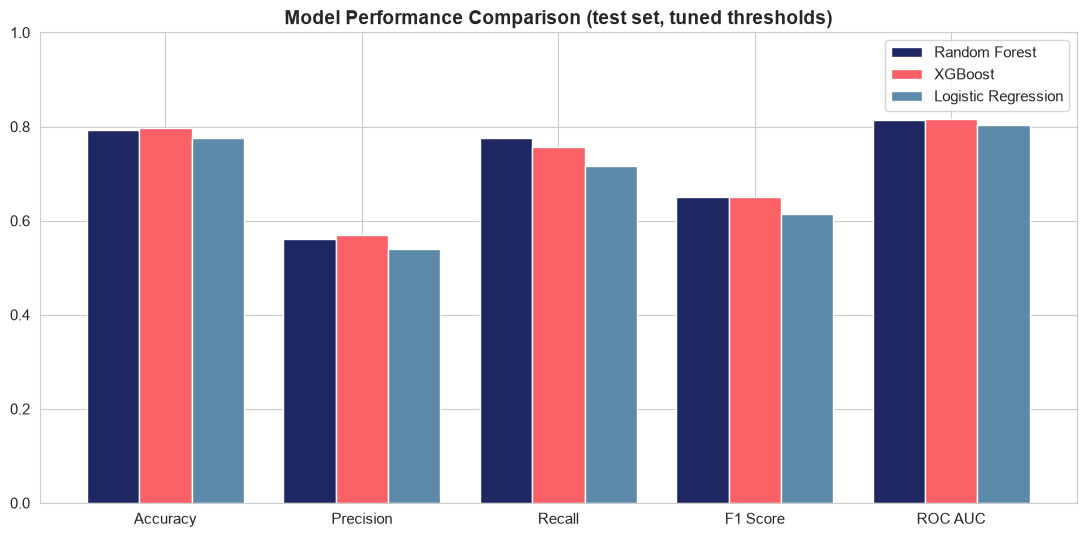

In [23]:
metric_names = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
x = np.arange(len(metric_names))
n_models = len(results)
width = 0.8 / n_models

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, (_, row) in enumerate(results.iterrows()):
    offset = (i - (n_models - 1) / 2) * width
    ax.bar(x + offset, row[metric_names].values.astype(float), width,
           label=row["Model"], color=SERIES[i % len(SERIES)], edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_title("Model Performance Comparison (test set, tuned thresholds)")
ax.legend()
plt.tight_layout()
plt.show()

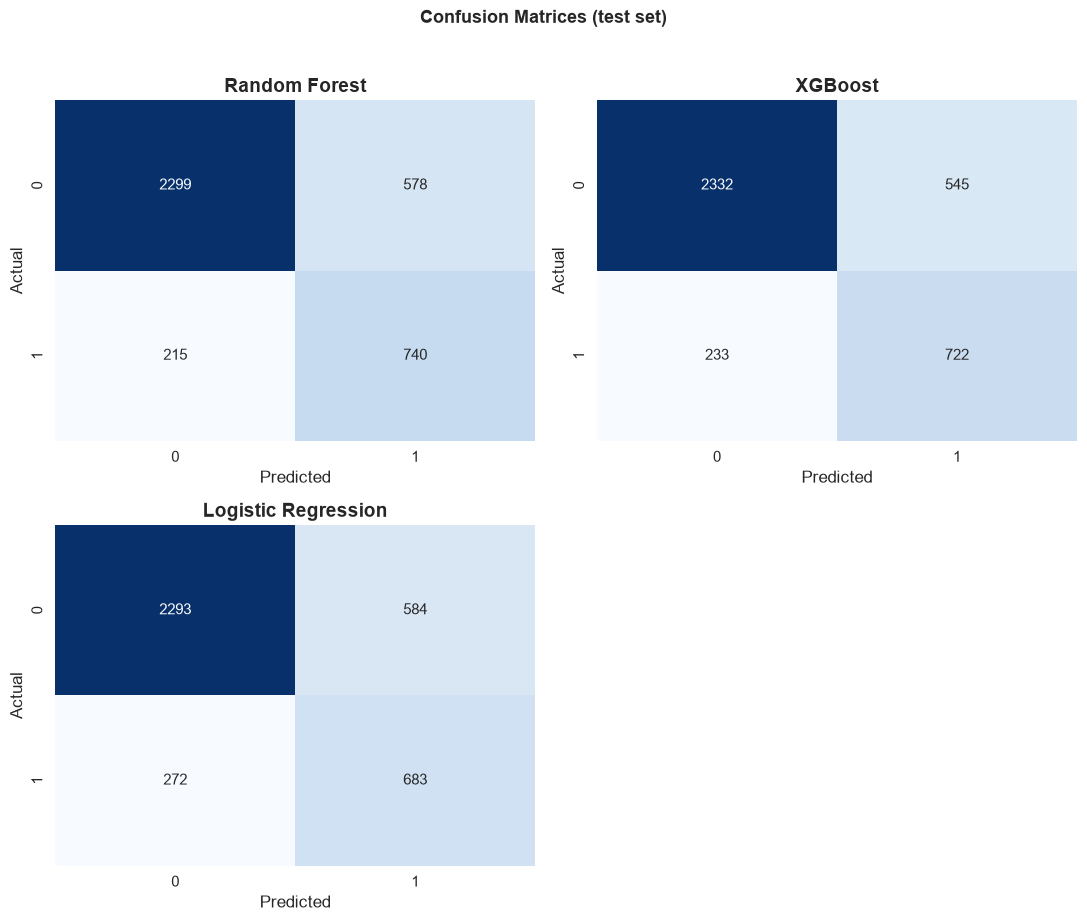

In [24]:
n_models = len(results)
n_cols = 2
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 4.5 * n_rows))
axes = np.atleast_1d(axes).ravel()

for i, (_, row) in enumerate(results.iterrows()):
    r = RESULTS[row["Model"]]
    cm = confusion_matrix(y_test, r["pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False)
    axes[i].set_title(row["Model"])
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Confusion Matrices (test set)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

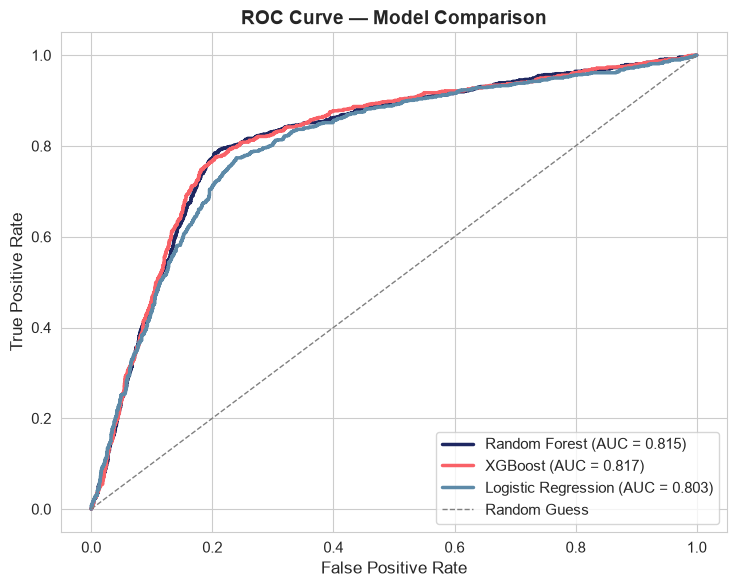

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 6))
colors = dict(zip(results["Model"], SERIES))

for _, row in results.iterrows():
    r = RESULTS[row["Model"]]
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    ax.plot(fpr, tpr, lw=2.5, color=colors[row["Model"]],
            label=f'{row["Model"]} (AUC = {row["ROC AUC"]:.3f})')

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1, label="Random Guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Model Comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [26]:
champion_name = results.iloc[0]["Model"]
champion = RESULTS[champion_name]["model"]
champion_info = RESULTS[champion_name]
print(f"Champion model — selected by VALIDATION AUPRC (test set not used for selection): {champion_name}")

Champion model — selected by VALIDATION AUPRC (test set not used for selection): Random Forest


## 14. Cross-Validation Robustness Check

The champion is re-scored with 5-fold stratified cross-validation on the training data —
a stability and generalization sanity check independent of the single test split.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

if champion_name == "Logistic Regression":
    cv_auc = cross_val_score(champion, X_train_scaled, y_train,
                             cv=cv, scoring="roc_auc", n_jobs=1)
else:
    cv_auc = cross_val_score(champion, X_train_arr, y_train,
                             cv=cv, scoring="roc_auc", n_jobs=1)

print(f"5-fold CV ROC AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")
print(f"Held-out test ROC AUC: {roc_auc_score(y_test, RESULTS[champion_name]['proba']):.3f}")

5-fold CV ROC AUC: 0.801 ± 0.009
Held-out test ROC AUC: 0.815


## 15. Business Insights — Most Important Hiring Factors

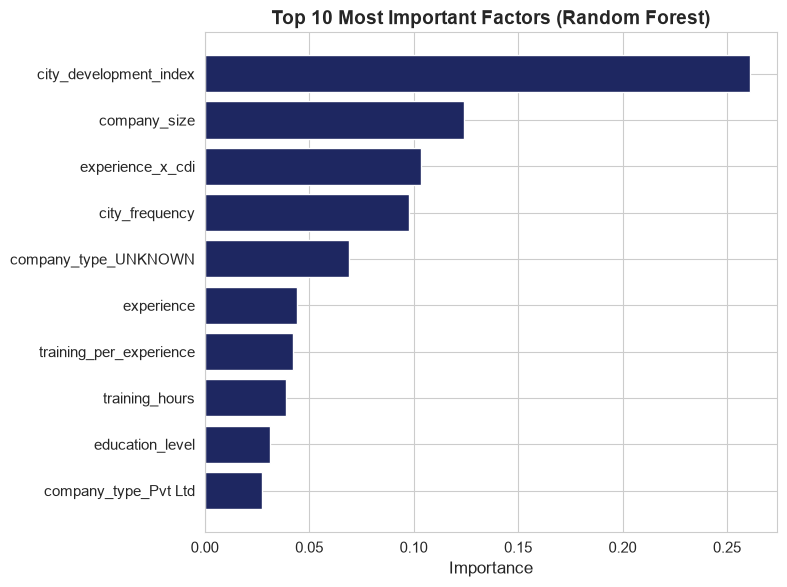

city_development_index     0.260887
company_size               0.124114
experience_x_cdi           0.103718
city_frequency             0.097564
company_type_UNKNOWN       0.068834
experience                 0.044379
training_per_experience    0.042219
training_hours             0.038825
education_level            0.031019
company_type_Pvt Ltd       0.027263
dtype: float64

In [28]:
if hasattr(champion, "feature_importances_"):
    importances = pd.Series(champion.feature_importances_, index=feature_names)
elif champion_name == "Logistic Regression":
    importances = pd.Series(np.abs(champion.coef_[0]), index=feature_names)
importances = importances.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top10 = importances.head(10).sort_values()
ax.barh(top10.index, top10.values, color=PRIMARY)
ax.set_title(f"Top 10 Most Important Factors ({champion_name})")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

importances.head(10)

**Business interpretation (champion = Random Forest):**
- **Where a candidate lives dominates the prediction:** city development index alone carries
  0.261 importance, and adding the city-frequency measure and the engineered
  experience×CDI interaction puts roughly a third of total importance on geography alone.
- **Current employer context beats credentials:** company size (0.124) and company type sit above
  every academic feature — consistent with the EDA finding that ~2 in 5 candidates with an
  *unknown* company size are looking for a change.
- **Engagement signals are moderate:** experience, training-per-experience and training hours
  land in the 0.04-0.05 band — real but secondary.
- **Missing info is still a signal:** the "not stated" company-type flag ranks fifth (0.069), and
  the tied runner-up (XGBoost) places both "not stated" flags (major, company type) in its top
  five — so profile completeness separates candidates across models.
- **Education level ranks low** — academic background alone is a weak predictor of job-change intent.
- **Recommendation:** weight current employment context, geography and engagement more heavily
  than academic credentials when prioritizing outreach.

---
## 16. Bonus — Candidate Ranking System (on unseen candidates)

The champion model scores the held-out **test set** — candidates the model never saw during
training or threshold tuning, making this ranking operationally realistic. A recruiter would
contact the top of this list first.

In [29]:
test_probs = champion.predict_proba(
    X_test_scaled if champion_name == "Logistic Regression" else X_test_arr
)[:, 1]

ranking = pd.DataFrame({
    "enrollee_id": df.loc[X_test.index, "enrollee_id"].values,
    "predicted_probability": test_probs,
    "actually_looking": y_test.values,
}).sort_values("predicted_probability", ascending=False).reset_index(drop=True)

top_10_candidates = ranking.head(10).copy()
top_10_candidates["predicted_probability"] = top_10_candidates["predicted_probability"].round(3)
print("Top 10 ranked candidates (from the unseen test set):")
top_10_candidates

Top 10 ranked candidates (from the unseen test set):


,enrollee_id,predicted_probability,actually_looking
0,19395,0.864,0.0
1,10515,0.862,1.0
2,11464,0.855,1.0
3,18675,0.853,0.0
4,6539,0.852,0.0
5,1993,0.851,1.0
6,19399,0.850,1.0
7,30755,0.849,0.0
8,12385,0.849,1.0
9,18148,0.848,0.0


Base rate of job-seekers in the pool      : 24.9%
Hit rate in the top 10% ranked candidates : 61.4%
Recruiter productivity lift               : 2.5×


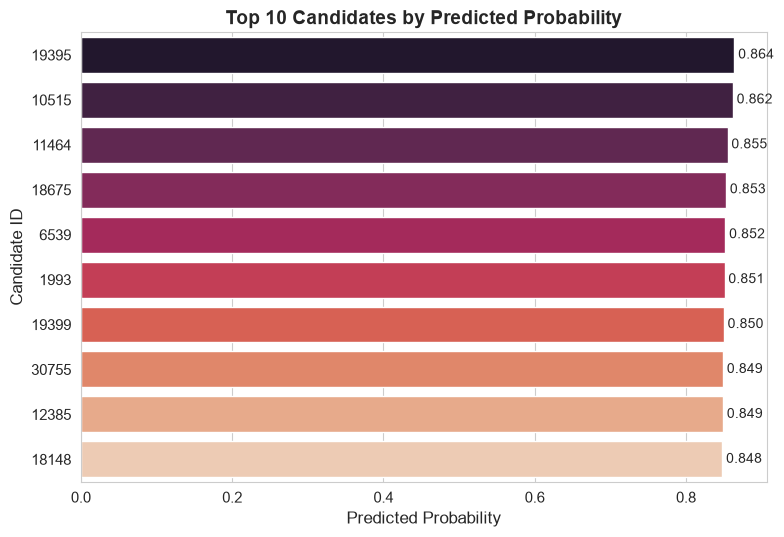

In [30]:
k = max(1, int(len(ranking) * 0.10))
top_k_hit_rate = ranking.head(k)["actually_looking"].mean()
base_rate = ranking["actually_looking"].mean()

print(f"Base rate of job-seekers in the pool      : {base_rate:.1%}")
print(f"Hit rate in the top 10% ranked candidates : {top_k_hit_rate:.1%}")
print(f"Recruiter productivity lift               : {top_k_hit_rate / base_rate:.1f}×")

fig, ax = plt.subplots(figsize=(8, 5.5))
plot_data = top_10_candidates.copy()
plot_data["enrollee_id"] = plot_data["enrollee_id"].astype(str)
sns.barplot(x="predicted_probability", y="enrollee_id", data=plot_data,
            order=plot_data["enrollee_id"], hue="enrollee_id",
            palette="rocket", legend=False, ax=ax)
ax.set_title("Top 10 Candidates by Predicted Probability")
ax.set_xlabel("Predicted Probability")
ax.set_ylabel("Candidate ID")
for i, v in enumerate(plot_data["predicted_probability"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=10)
plt.tight_layout()
plt.show()


## 17. Conclusions & Recommendations

**Model selection:** the champion is chosen on the **validation AUPRC** — the discrimination metric
that best matches the ranking use case — with the F1-maximizing threshold per model tuned on
validation and the champion selected *without ever looking at the test set*. Features, thresholds,
hyperparameters and the champion itself are all fitted before test evaluation, so the reported
numbers are unbiased estimates of real-world performance.

**Recall matters here.** In recruitment, missing a genuinely motivated candidate (false negative)
costs more than one extra phone call (false positive) — so the F1-tuned threshold favors catching
job-seekers while keeping precision workable.

**Key hiring signals:** current employment context (company size/type, city development index)
outweighs academic background in predicting job-change intent. HR outreach strategies should be
adjusted accordingly.

**Practical use:** Section 16 shows the ranking system in action — a productivity lift for
recruiters, automatically surfacing the highest-probability candidates as new applications arrive.

**Deployed:** the full pipeline (model, scaler, encodings, threshold, top-features) is serialized in
Section 18 as `recruitment_champion.pkl` and served by the accompanying Streamlit dashboard
(`app.py`) — a working display version comes with this submission.

**Limitations & future work:**
- Calibrate probabilities (e.g. isotonic/Platt) if the dashboard is to show absolute probabilities
- Add richer engineered features (e.g. salary expectations if available)
- Retrain periodically as new applicant data becomes available, to avoid model drift
- Extend the Streamlit demo to a hosted deployment + REST API for real recruiters
---

---
## 18. Data Citation & Saved Artifacts (for deployment)

**Dataset citation** — Kaggle: *HR Analytics: Job Change of Data Scientists*,
uploaded by `<author>` (see the Kaggle dataset page for the canonical DOI/citation),
~19,158 labelled candidate profiles. Used for the Artificial Intelligence Professional Diploma
Graduation Project (Project 2). All preprocessing is reproducible from `aug_train.csv` alone.

The cell below packages everything a deployment needs:
- **`recruitment_champion.pkl`** — model + scaler + feature names + city frequencies + tuned threshold
- **`processed_dataset.csv`** — cleaned/engineered human-readable dataset
- **`processed_candidates_encoded.csv`** — final encoded features ready for retraining
- **`test_scores.csv`** — champion scores on the untouched test set (used for percentile lookup)

In [31]:
import os, joblib

# 1) Human-readable processed dataset (deterministic cleaning + train-fit medians + engineered features)
df_processed = engineer(df[feature_cols], experience_median, last_new_job_median)
df_processed.insert(0, "enrollee_id", df.loc[df_processed.index, "enrollee_id"])
df_processed["target"] = y.loc[df_processed.index]
df_processed.round(4).to_csv("processed_dataset.csv", index=False)

# 2) Encoded training matrix (the exact 34 features the champion consumes)
X_all_enc = pd.concat([X_train_enc, X_val_enc, X_test_enc]).sort_index()
enc_dataset = X_all_enc.copy()
enc_dataset.insert(0, "enrollee_id", df.loc[enc_dataset.index, "enrollee_id"])
enc_dataset["target"] = y.loc[enc_dataset.index]
enc_dataset["split"] = np.where(enc_dataset.index.isin(X_test_enc.index), "test",
                        np.where(enc_dataset.index.isin(X_val_enc.index), "validation", "train"))
enc_dataset.to_csv("processed_candidates_encoded.csv", index=False)

# 3) Deployment bundle: everything the dashboard needs to score a candidate with zero leakage
bundle = {
    "model": champion,
    "model_name": champion_name,
    "scaler": scaler,
    "feature_names": feature_names,
    "threshold": champion_info["threshold"],
    "city_freq": city_freq,
    "trained_on": "aug_train.csv (19,158 rows) — stratified 64/16/20 split, random_state=42",
    "val_auprc": champion_info["val_ap"],
    "test_metrics": results.set_index("Model").loc[champion_name].to_dict(),
    "test_scores": ranking[["enrollee_id", "predicted_probability", "actually_looking"]].copy(),
}
joblib.dump(bundle, "recruitment_champion.pkl")

# 4) Small helper files
results.round(3).to_csv("model_comparison.csv", index=False)
ranking.to_csv("test_scores.csv", index=False)

print("Saved deployment artifacts (random_state=42 makes every file bit-reproducible):")
for f in ["recruitment_champion.pkl", "processed_dataset.csv",
          "processed_candidates_encoded.csv", "model_comparison.csv", "test_scores.csv"]:
    size = os.path.getsize(f) / 1024
    print(f"  {f:<38} {size:>8.1f} KB")

Saved deployment artifacts (random_state=42 makes every file bit-reproducible):
  recruitment_champion.pkl                13252.9 KB
  processed_dataset.csv                    2388.5 KB
  processed_candidates_encoded.csv         2442.8 KB
  model_comparison.csv                        0.2 KB
  test_scores.csv                           112.3 KB
